# Branch-Invariant Wrapped-DD Pairwise Experiment

This notebook tests whether the mixed-tracking spoof group can be recovered **without selecting an integer branch $m$**. It works directly in carrier cycles, wraps pairwise residuals modulo one cycle, and treats all eligible PRNs identically. There is no temporal DP, ephemeris-aligned best-m, known-label reference selection, or authentic calibration recording.

The controlled spoof PRNs are introduced only in the final post-hoc evaluation. Until then, the candidate group is selected from the topology of a low-collapse pair graph.

## Branch-invariant method

Let $s_{i,k}$ be the two-receiver single difference for PRN $i$ in carrier cycles, $\rho=D/\lambda$, and $\mu^{eph}_{i,k}=\cos\alpha^{eph}_{i,k}$. For pair $(i,j)$, define

$$y_{ij,k}=s_{i,k}-s_{j,k},\qquad e_{ij,k}=\rho(\mu^{eph}_{i,k}-\mu^{eph}_{j,k}).$$

With $\operatorname{wrap}(x)=((x+1/2)\bmod 1)-1/2$, the branch-invariant geometry residual is

$$q^{wrap}_{ij,k}=\left|\operatorname{wrap}(y_{ij,k}-e_{ij,k})\right|.$$

Any integer ambiguity in $y_{ij,k}$ disappears modulo one cycle. Ephemeris is therefore used only as the geometry hypothesis being tested, not to select a fitted branch.

A synchronized common-source spoofer should also produce

$$c_{ij,k}=\left|\operatorname{wrap}(y_{ij,k})\right|\approx 0$$

for pairs inside the spoof group. The experiment estimates an exploratory two-component GMM threshold for the epoch-median $\overline c_{ij}$, creates an edge when $\overline c_{ij}$ is below that threshold, finds maximal complete subgraphs, and ranks them by largest clique size followed by smallest median collapse. This ranking is label-free but exploratory.

In [1]:
from itertools import combinations
from pathlib import Path
import importlib

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import seaborn as sns

import aoa_pipeline
importlib.reload(aoa_pipeline)

from aoa_pipeline import (
    DatasetConfig,
    aggregate_wrapped_pairwise_residuals,
    compute_wrapped_pairwise_residuals,
    estimate_pairwise_threshold_gmm,
    find_pairwise_cliques,
    run_dataset,
)

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")

## Label-free experiment configuration

The first 34 synchronized one-second epochs are fixed by the controlled mixed-tracking interval. Satellite eligibility uses only measurement and ephemeris availability. `COLLAPSE_THRESHOLD_MODE='unsupervised_gmm'` estimates the graph threshold from the mixed pair distribution and is not a calibrated publication threshold. An externally predeclared threshold can be supplied for a later confirmatory run.

In [2]:
OUTPUT_DIR = Path("outputs/aoa_paper/wrapped_pairwise_classifier")
SAVE_OUTPUTS = False

MIXED_START_INDEX = 0
MIXED_ANALYSIS_LENGTH = 34
MIN_TARGET_EPOCHS = 20
MIN_PAIR_EPOCHS = 10
BASELINE_OVER_WAVELENGTH = 1.0
MIN_CLIQUE_SIZE = 3

COLLAPSE_THRESHOLD_MODE = "unsupervised_gmm"  # unsupervised_gmm or external
EXTERNAL_COLLAPSE_THRESHOLD = None
if COLLAPSE_THRESHOLD_MODE not in {"unsupervised_gmm", "external"}:
    raise ValueError("COLLAPSE_THRESHOLD_MODE must be 'unsupervised_gmm' or 'external'.")
if COLLAPSE_THRESHOLD_MODE == "external":
    if EXTERNAL_COLLAPSE_THRESHOLD is None:
        raise ValueError("Set EXTERNAL_COLLAPSE_THRESHOLD for external mode.")
    if float(EXTERNAL_COLLAPSE_THRESHOLD) < 0:
        raise ValueError("EXTERNAL_COLLAPSE_THRESHOLD must be non-negative.")

MIXED_CONFIG = DatasetConfig(
    name="wrapped_pairwise_classifier/mixed_tracking",
    receiver1_path=Path("dataset/sp-partial-19-06/18-06/COM3___9600_260618_095042.ubx"),
    receiver2_path=Path("dataset/sp-partial-19-06/18-06/COM4___9600_260618_095054.ubx"),
    start_index=MIXED_START_INDEX,
    length=MIXED_ANALYSIS_LENGTH,
    alpha_r_deg=None,
    reference_svid=None,
    selected_svids=None,
    excluded_reference_svids=None,
    reference_required_svids=None,
    excluded_analysis_svids=None,
    sync_tow_decimals=0,
    use_navpvt_time_correction=True,
    single_difference_order="rx2-rx1",
    navsat_azimuth_bias_deg=0.0,
    baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
)

def show_figure(fig, filename):
    if SAVE_OUTPUTS:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(OUTPUT_DIR / filename, dpi=220, bbox_inches="tight")
    display(fig)
    plt.close(fig)

pd.DataFrame([{
    "dataset": "Mixed tracking",
    "epochs": MIXED_CONFIG.length,
    "baseline_over_wavelength": BASELINE_OVER_WAVELENGTH,
    "collapse_threshold_mode": COLLAPSE_THRESHOLD_MODE,
    "uses_integer_branch_selection": False,
    "uses_authentic_calibration": False,
}])

,dataset,epochs,baseline_over_wavelength,collapse_threshold_mode,uses_integer_branch_selection,uses_authentic_calibration
0,Mixed tracking,34,1.0,unsupervised_gmm,False,False


## Prepare synchronized mixed-tracking observables

`run_dataset` supplies synchronized receiver single differences and epoch-matched ephemeris AoA. The wrapped experiment does not consume its DP-selected AoA tracks.

In [3]:
mixed_run = run_dataset(MIXED_CONFIG)

available_svids = sorted(
    set(map(int, mixed_run.single_difference_cycles.columns))
    | set(map(int, mixed_run.ephemeris_aoa_deg.columns))
)
availability = pd.DataFrame({
    "svid": available_svids,
    "single_difference_epochs": [
        int(mixed_run.single_difference_cycles.get(svid, pd.Series(dtype=float)).notna().sum())
        for svid in available_svids
    ],
    "ephemeris_epochs": [
        int(mixed_run.ephemeris_aoa_deg.get(svid, pd.Series(dtype=float)).notna().sum())
        for svid in available_svids
    ],
}).assign(
    eligible=lambda frame: frame[["single_difference_epochs", "ephemeris_epochs"]]
    .min(axis=1).ge(MIN_TARGET_EPOCHS)
)
print(f"Synchronized epochs: {len(mixed_run.epochs)}")
display(availability)

Synchronized epochs: 34


,svid,single_difference_epochs,ephemeris_epochs,eligible
0,6,34,30,True
1,9,34,30,True
2,10,34,34,True
3,11,34,30,True
4,12,34,34,True
5,13,34,0,False
6,15,34,34,True
7,18,34,34,True
8,20,34,30,True
9,23,34,34,True


## Compute branch-free pair statistics

Each satellite pair is evaluated directly from the two receiver single differences. A third satellite reference is unnecessary: subtracting two single differences already forms the required inter-satellite double difference, and any alternative DD reference cancels modulo one cycle.

In [4]:
wrapped_epoch_residuals = compute_wrapped_pairwise_residuals(
    mixed_run.single_difference_cycles,
    mixed_run.ephemeris_aoa_deg,
    min_target_epochs=MIN_TARGET_EPOCHS,
    baseline_over_wavelength=BASELINE_OVER_WAVELENGTH,
)
wrapped_aggregated_pairs = aggregate_wrapped_pairwise_residuals(
    wrapped_epoch_residuals, min_epochs_per_pair=MIN_PAIR_EPOCHS
)
eligible_svids = sorted(
    set(wrapped_aggregated_pairs.left_svid.astype(int))
    | set(wrapped_aggregated_pairs.right_svid.astype(int))
)
summary = pd.DataFrame([{
    "eligible_satellites": len(eligible_svids),
    "eligible_svids": tuple(eligible_svids),
    "epoch_pair_observations": len(wrapped_epoch_residuals),
    "aggregated_pairs": len(wrapped_aggregated_pairs),
}])
display(summary)
display(wrapped_aggregated_pairs.sort_values("median_common_source_collapse").round(4))

,eligible_satellites,eligible_svids,epoch_pair_observations,aggregated_pairs
0,11,"(6, 9, 10, 11, 12, 15, 18, 20, 23, 24, 32)",1724,55


,left_svid,right_svid,median_wrapped_geometry_residual,mean_wrapped_geometry_residual,p90_wrapped_geometry_residual,median_common_source_collapse,mean_common_source_collapse,p90_common_source_collapse,median_expected_separation,median_common_source_incompatibility,epoch_count,pair
30,11,20,0.3348,0.3344,0.3421,0.0030,0.0048,0.0121,0.3351,0.3321,30,PRN 11–PRN 20
15,9,20,0.0915,0.0929,0.1013,0.0039,0.0049,0.0104,0.0921,0.0882,30,PRN 9–PRN 20
11,9,11,0.4285,0.4273,0.4342,0.0044,0.0054,0.0121,0.4271,0.4227,30,PRN 9–PRN 11
2,6,11,0.3332,0.3324,0.3515,0.0103,0.0134,0.0277,0.3319,0.3216,30,PRN 6–PRN 11
0,6,9,0.0952,0.0949,0.1149,0.0107,0.0132,0.0244,0.0952,0.0845,30,PRN 6–PRN 9
6,6,20,0.0092,0.0127,0.0256,0.0108,0.0128,0.0238,0.0032,-0.0077,30,PRN 6–PRN 20
44,15,32,0.1614,0.1709,0.2650,0.0367,0.0911,0.3644,0.1797,0.1430,33,PRN 15–PRN 32
37,12,23,0.2121,0.2136,0.2404,0.0384,0.0386,0.0583,0.2506,0.2121,34,PRN 12–PRN 23
46,18,23,0.0305,0.0330,0.0498,0.0406,0.0437,0.0786,0.0714,0.0290,34,PRN 18–PRN 23
40,15,18,0.1115,0.1090,0.1413,0.0553,0.0553,0.0851,0.0562,0.0009,34,PRN 15–PRN 18


## Exploratory pair-distribution thresholds

Two-component GMMs are fitted separately to the 55 wrapped geometry residuals and common-source collapse values. The geometry split is diagnostic only. The collapse split creates candidate graph edges. BIC values are shown to expose whether two components are supported; neither split is equivalent to an independently calibrated threshold.

,threshold_mode,value_column,pair_count,estimated_threshold,low_component_mean,low_component_std,low_component_weight,high_component_mean,high_component_std,high_component_weight,one_component_bic,two_component_bic,bic_improvement_for_two_components
0,unsupervised_gmm_exploratory,median_wrapped_geometry_residual,55,0.233193,0.112182,0.064350,0.682907,0.338751,0.097754,0.317093,-60.089158,-62.234146,2.144988
1,unsupervised_gmm_exploratory,median_common_source_collapse,55,0.092524,0.031768,0.029764,0.210113,0.302215,0.100076,0.789887,-50.420898,-55.102677,4.681779


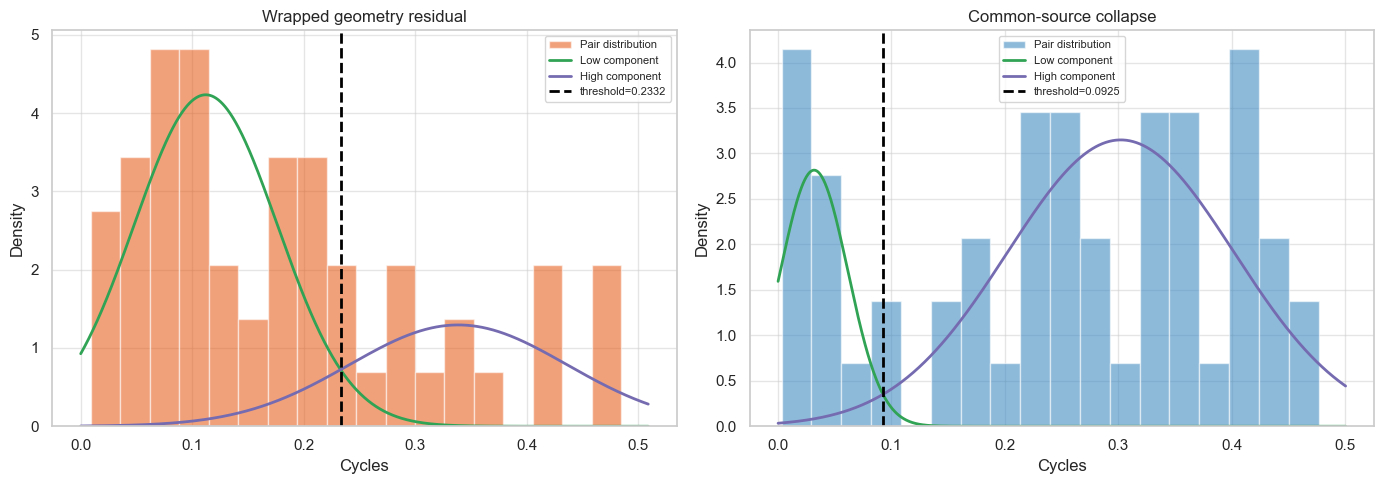

In [5]:
geometry_threshold, geometry_gmm = estimate_pairwise_threshold_gmm(
    wrapped_aggregated_pairs,
    value_column="median_wrapped_geometry_residual",
    random_state=0,
)
if COLLAPSE_THRESHOLD_MODE == "unsupervised_gmm":
    collapse_threshold, collapse_gmm = estimate_pairwise_threshold_gmm(
        wrapped_aggregated_pairs,
        value_column="median_common_source_collapse",
        random_state=0,
    )
else:
    collapse_threshold = float(EXTERNAL_COLLAPSE_THRESHOLD)
    collapse_gmm = pd.DataFrame([{
        "threshold_mode": "external",
        "value_column": "median_common_source_collapse",
        "estimated_threshold": collapse_threshold,
        "pair_count": len(wrapped_aggregated_pairs),
    }])
threshold_summary = pd.concat([geometry_gmm, collapse_gmm], ignore_index=True)
display(threshold_summary.round(6))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column, model, threshold, title, color in [
    (axes[0], "median_wrapped_geometry_residual", geometry_gmm, geometry_threshold, "Wrapped geometry residual", "#e6550d"),
    (axes[1], "median_common_source_collapse", collapse_gmm, collapse_threshold, "Common-source collapse", "#3182bd"),
]:
    values = wrapped_aggregated_pairs[column].astype(float)
    ax.hist(values, bins=18, density=True, alpha=0.55, color=color, label="Pair distribution")
    if "low_component_mean" in model.columns:
        row = model.iloc[0]
        grid = np.linspace(0, max(0.5, values.max() * 1.05), 1000)
        for prefix, component_color in (("low", "#31a354"), ("high", "#756bb1")):
            mean = row[f"{prefix}_component_mean"]
            std = row[f"{prefix}_component_std"]
            weight = row[f"{prefix}_component_weight"]
            density = weight / (std * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((grid - mean) / std) ** 2)
            ax.plot(grid, density, color=component_color, lw=2, label=f"{prefix.title()} component")
    ax.axvline(threshold, color="black", ls="--", lw=2, label=f"threshold={threshold:.4f}")
    ax.set_xlabel("Cycles")
    ax.set_ylabel("Density")
    ax.set_title(title)
    ax.legend(fontsize=8)
fig.tight_layout()
show_figure(fig, "wrapped_pair_distributions_and_thresholds.png")

## Every pairwise wrapped value

The heatmaps and sorted bar charts expose all 55 pair values. A small collapse value means that two received signals exhibit nearly the same inter-antenna phase modulo one cycle. It is not, by itself, proof of spoofing; the clique topology and expected ephemeris separation supply additional context.

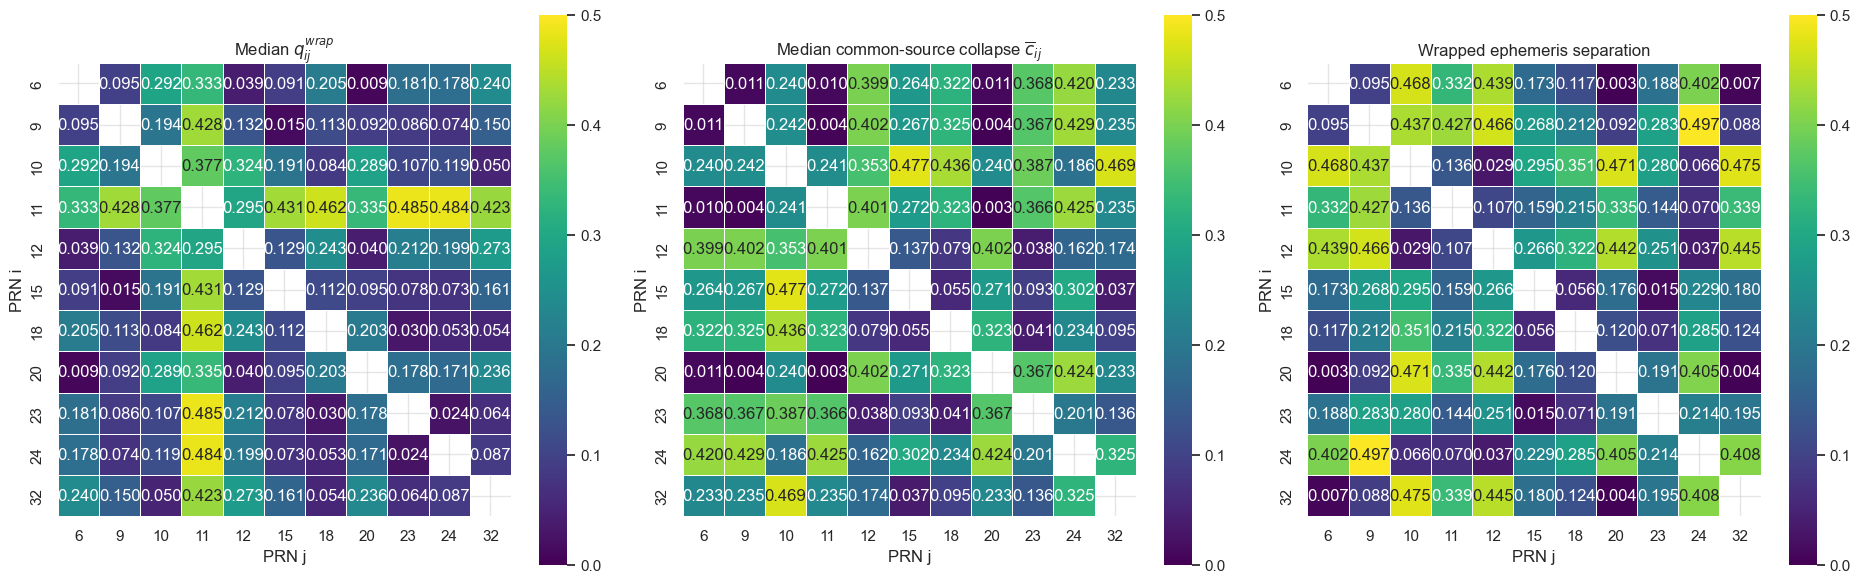

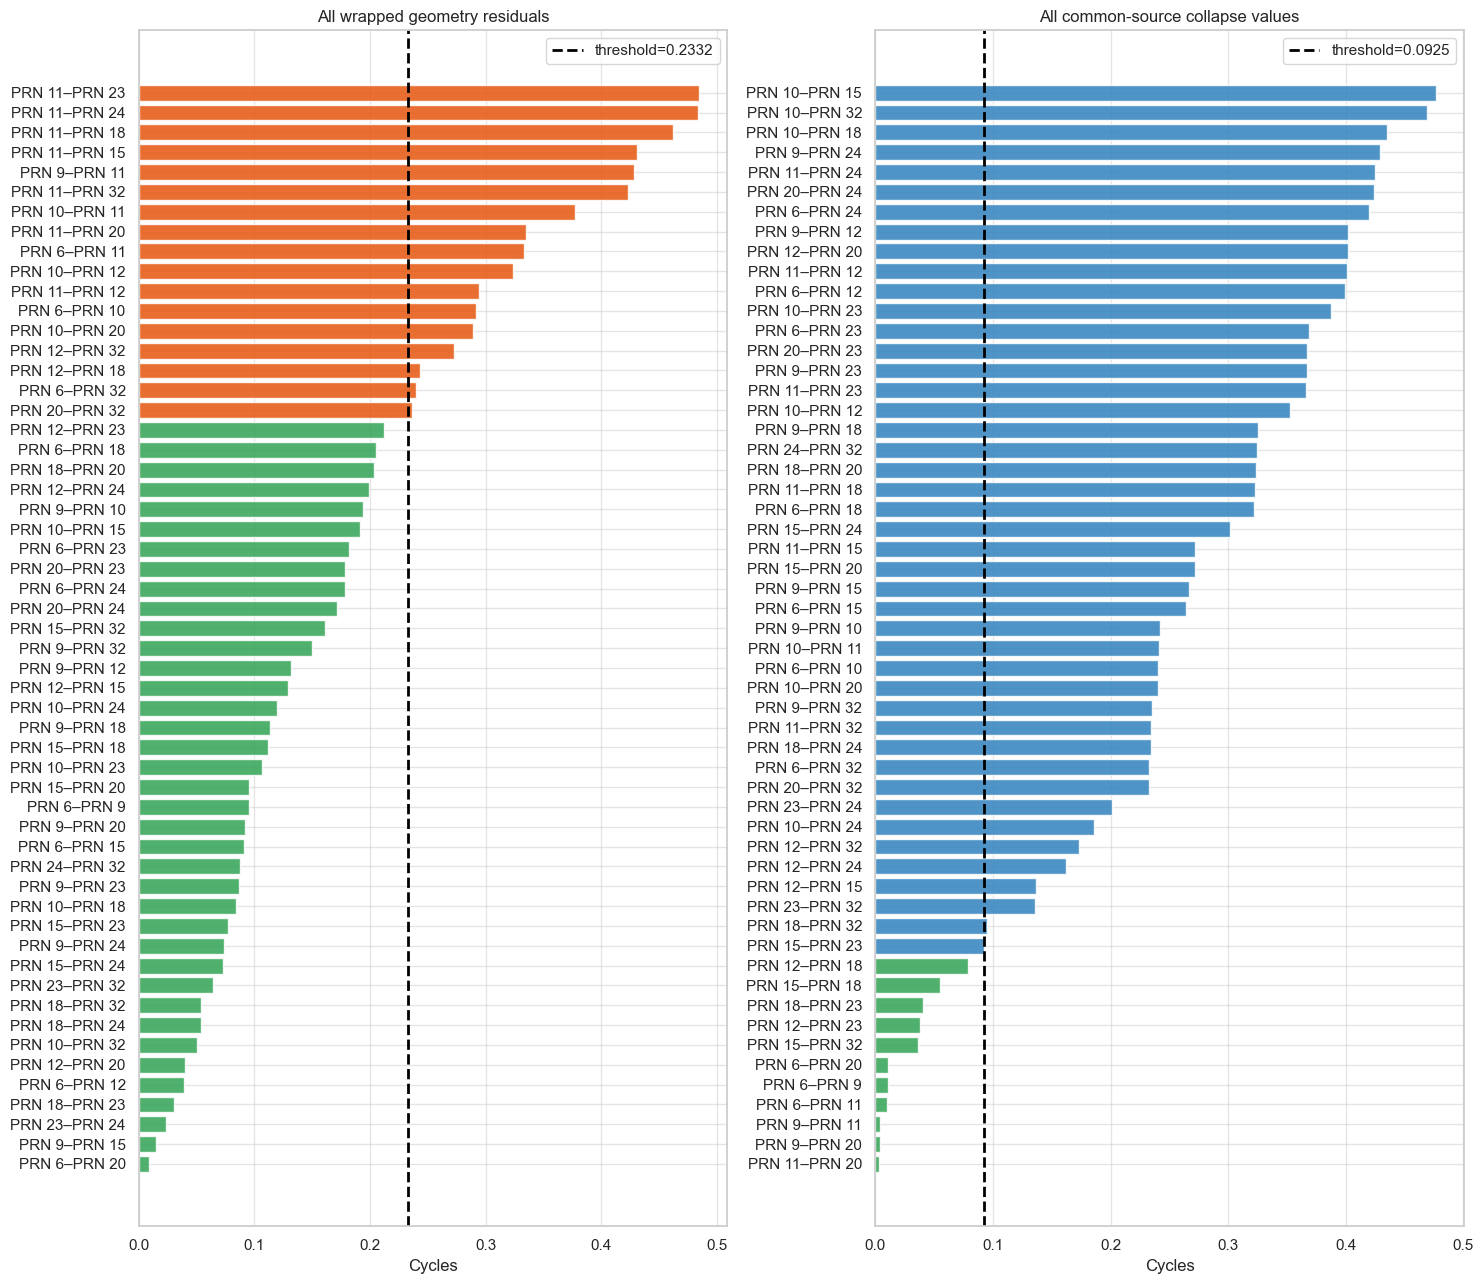

In [6]:
def symmetric_pair_matrix(frame, value_column):
    matrix = pd.DataFrame(np.nan, index=eligible_svids, columns=eligible_svids, dtype=float)
    for row in frame.itertuples():
        left, right = int(row.left_svid), int(row.right_svid)
        matrix.loc[left, right] = matrix.loc[right, left] = float(getattr(row, value_column))
    matrix.index.name = "PRN i"
    matrix.columns.name = "PRN j"
    return matrix

geometry_matrix = symmetric_pair_matrix(wrapped_aggregated_pairs, "median_wrapped_geometry_residual")
collapse_matrix = symmetric_pair_matrix(wrapped_aggregated_pairs, "median_common_source_collapse")
expected_matrix = symmetric_pair_matrix(wrapped_aggregated_pairs, "median_expected_separation")

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, matrix, title in [
    (axes[0], geometry_matrix, r"Median $q^{wrap}_{ij}$"),
    (axes[1], collapse_matrix, r"Median common-source collapse $\overline{c}_{ij}$"),
    (axes[2], expected_matrix, "Wrapped ephemeris separation"),
]:
    sns.heatmap(matrix, annot=True, fmt=".3f", cmap="viridis", vmin=0, vmax=0.5, square=True, linewidths=0.4, ax=ax)
    ax.set_title(title)
fig.tight_layout()
show_figure(fig, "wrapped_geometry_collapse_expected_heatmaps.png")

fig, axes = plt.subplots(1, 2, figsize=(15, 13), sharey=False)
for ax, column, threshold, title, color in [
    (axes[0], "median_wrapped_geometry_residual", geometry_threshold, "All wrapped geometry residuals", "#e6550d"),
    (axes[1], "median_common_source_collapse", collapse_threshold, "All common-source collapse values", "#3182bd"),
]:
    plotted = wrapped_aggregated_pairs.sort_values(column, ascending=True)
    colors = np.where(plotted[column].le(threshold), "#31a354", color)
    ax.barh(plotted.pair, plotted[column], color=colors, alpha=0.85)
    ax.axvline(threshold, color="black", ls="--", lw=2, label=f"threshold={threshold:.4f}")
    ax.set_xlabel("Cycles")
    ax.set_title(title)
    ax.legend()
fig.tight_layout()
show_figure(fig, "all_wrapped_pair_values.png")

## Label-free low-collapse clique search

An edge is created when the median common-source collapse is below the selected threshold. All maximal complete subgraphs of at least three satellites are listed. The candidate common-source group is the largest clique; ties are resolved by lower median internal collapse. This computational path is label-isolated: controlled labels do not enter its inputs or ranking. The rule itself remains exploratory until confirmed on independent data.

,clique_svids,clique_size,edge_count,median_edge_value,max_edge_value,edge_threshold
0,"(6, 9, 11, 20)",4,6,0.00736,0.01082,0.09252
1,"(12, 18, 23)",3,3,0.04061,0.07894,0.09252


Selected common-source candidate group: (6, 9, 11, 20)
Unique largest clique: True


,pair,median_common_source_collapse,median_expected_separation,median_wrapped_geometry_residual,epoch_count
30,PRN 11–PRN 20,0.00302,0.33508,0.33481,30
15,PRN 9–PRN 20,0.00390,0.09206,0.09153,30
11,PRN 9–PRN 11,0.00439,0.42713,0.42847,30
2,PRN 6–PRN 11,0.01033,0.33192,0.33315,30
0,PRN 6–PRN 9,0.01072,0.09522,0.09519,30
6,PRN 6–PRN 20,0.01082,0.00316,0.00922,30


,candidate_group,group_size,internal_pair_count,median_internal_collapse,max_internal_collapse,median_internal_expected_separation,median_internal_geometry_residual
0,"(6, 9, 11, 20)",4,6,0.00736,0.01082,0.21357,0.21417


,svid,reported_group
0,6,Common-source candidate
1,9,Common-source candidate
2,10,Other tracked source
3,11,Common-source candidate
4,12,Other tracked source
5,15,Other tracked source
6,18,Other tracked source
7,20,Common-source candidate
8,23,Other tracked source
9,24,Other tracked source


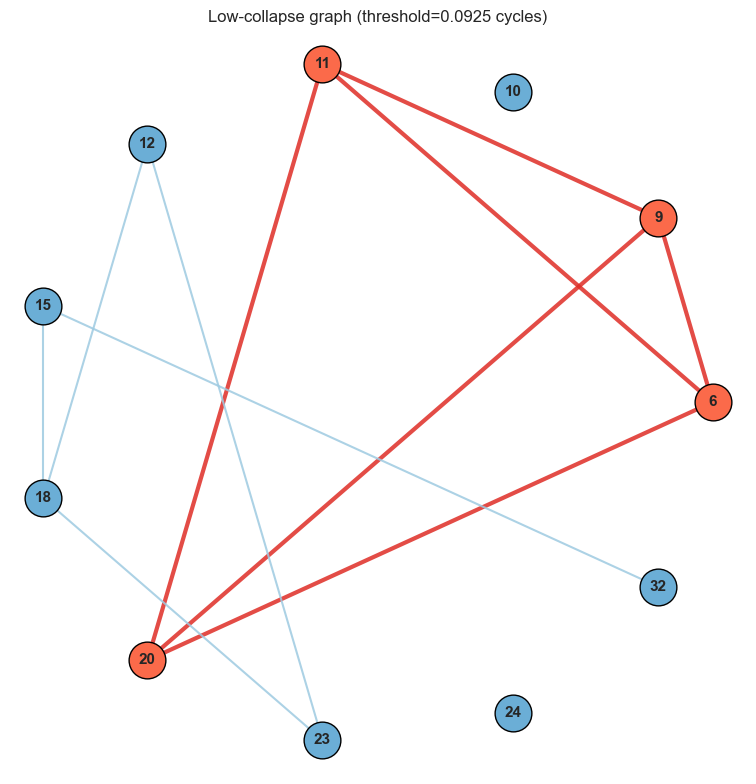

,collapse_threshold,top_group,top_group_size,matches_selected_group
0,0.005,"(9, 11, 20)",3,False
1,0.010,"(9, 11, 20)",3,False
2,0.015,"(6, 9, 11, 20)",4,True
3,0.020,"(6, 9, 11, 20)",4,True
4,0.025,"(6, 9, 11, 20)",4,True
5,0.030,"(6, 9, 11, 20)",4,True
6,0.035,"(6, 9, 11, 20)",4,True
7,0.040,"(6, 9, 11, 20)",4,True
8,0.045,"(6, 9, 11, 20)",4,True
9,0.050,"(6, 9, 11, 20)",4,True


In [7]:
candidate_cliques = find_pairwise_cliques(
    wrapped_aggregated_pairs,
    edge_value_column="median_common_source_collapse",
    edge_threshold=collapse_threshold,
    min_clique_size=MIN_CLIQUE_SIZE,
)
display(candidate_cliques.round(5))
if candidate_cliques.empty:
    raise RuntimeError("No complete low-collapse candidate group was found.")
largest_size = int(candidate_cliques.clique_size.max())
largest_candidates = candidate_cliques.loc[candidate_cliques.clique_size.eq(largest_size)]
selected_common_source_group = tuple(map(int, largest_candidates.iloc[0].clique_svids))
selection_is_unique_by_size = len(largest_candidates) == 1
print(f"Selected common-source candidate group: {selected_common_source_group}")
print(f"Unique largest clique: {selection_is_unique_by_size}")

selected_internal_pairs = wrapped_aggregated_pairs.loc[
    wrapped_aggregated_pairs.left_svid.isin(selected_common_source_group)
    & wrapped_aggregated_pairs.right_svid.isin(selected_common_source_group)
].sort_values("median_common_source_collapse")
display(selected_internal_pairs[[
    "pair", "median_common_source_collapse", "median_expected_separation",
    "median_wrapped_geometry_residual", "epoch_count",
]].round(5))

group_summary = pd.DataFrame([{
    "candidate_group": selected_common_source_group,
    "group_size": len(selected_common_source_group),
    "internal_pair_count": len(selected_internal_pairs),
    "median_internal_collapse": selected_internal_pairs.median_common_source_collapse.median(),
    "max_internal_collapse": selected_internal_pairs.median_common_source_collapse.max(),
    "median_internal_expected_separation": selected_internal_pairs.median_expected_separation.median(),
    "median_internal_geometry_residual": selected_internal_pairs.median_wrapped_geometry_residual.median(),
}])
display(group_summary.round(5))

satellite_groups = pd.DataFrame({"svid": eligible_svids})
satellite_groups["reported_group"] = satellite_groups.svid.map(
    lambda svid: "Common-source candidate" if int(svid) in selected_common_source_group else "Other tracked source"
)
display(satellite_groups)

fig, ax = plt.subplots(figsize=(8, 8))
angles = np.linspace(0, 2 * np.pi, len(eligible_svids), endpoint=False)
positions = {svid: (np.cos(angle), np.sin(angle)) for svid, angle in zip(eligible_svids, angles)}
low_collapse_edges = wrapped_aggregated_pairs.loc[
    wrapped_aggregated_pairs.median_common_source_collapse.le(collapse_threshold)
]
for row in low_collapse_edges.itertuples():
    x_values = [positions[int(row.left_svid)][0], positions[int(row.right_svid)][0]]
    y_values = [positions[int(row.left_svid)][1], positions[int(row.right_svid)][1]]
    internal = int(row.left_svid) in selected_common_source_group and int(row.right_svid) in selected_common_source_group
    ax.plot(x_values, y_values, color="#de2d26" if internal else "#9ecae1", lw=3 if internal else 1.5, alpha=0.85)
for svid, (x_value, y_value) in positions.items():
    selected = svid in selected_common_source_group
    ax.scatter(x_value, y_value, s=700, color="#fb6a4a" if selected else "#6baed6", edgecolor="black", zorder=3)
    ax.text(x_value, y_value, str(svid), ha="center", va="center", fontsize=11, fontweight="bold", zorder=4)
ax.set_title(f"Low-collapse graph (threshold={collapse_threshold:.4f} cycles)")
ax.set_aspect("equal")
ax.axis("off")
fig.tight_layout()
show_figure(fig, "low_collapse_pair_graph.png")

sensitivity_rows = []
for threshold in np.linspace(0.005, 0.15, 30):
    cliques = find_pairwise_cliques(
        wrapped_aggregated_pairs,
        edge_value_column="median_common_source_collapse",
        edge_threshold=float(threshold),
        min_clique_size=MIN_CLIQUE_SIZE,
    )
    top_group = tuple(cliques.iloc[0].clique_svids) if not cliques.empty else ()
    sensitivity_rows.append({
        "collapse_threshold": threshold,
        "top_group": top_group,
        "top_group_size": len(top_group),
        "matches_selected_group": set(top_group) == set(selected_common_source_group),
    })
threshold_sensitivity = pd.DataFrame(sensitivity_rows)
display(threshold_sensitivity)

## Post-hoc controlled-experiment evaluation

Only after the GMM threshold, graph, clique ranking, and reported satellite groups are computed are the NAVISIM labels introduced. Pair-class tables diagnose why the method succeeds or fails; they do not influence fitting or selection. This prevents computational label leakage but does not turn this exploratory experiment into a preregistered validation.

In [8]:
CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS = frozenset({6, 9, 11, 20})
evaluation = satellite_groups.copy()
evaluation["ground_truth"] = evaluation.svid.map(
    lambda svid: "Counterfeit" if int(svid) in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS else "Authentic"
)
evaluation["predicted_class"] = evaluation.reported_group.map({
    "Common-source candidate": "Counterfeit",
    "Other tracked source": "Authentic",
})
evaluation["correct"] = evaluation.predicted_class.eq(evaluation.ground_truth)
display(evaluation)
display(pd.crosstab(evaluation.ground_truth, evaluation.predicted_class, margins=True))

authentic_mask = evaluation.ground_truth.eq("Authentic")
counterfeit_mask = evaluation.ground_truth.eq("Counterfeit")
evaluation_summary = pd.DataFrame([{
    "authentic_accepted": int(evaluation.loc[authentic_mask, "predicted_class"].eq("Authentic").sum()),
    "authentic_total": int(authentic_mask.sum()),
    "counterfeit_detected": int(evaluation.loc[counterfeit_mask, "predicted_class"].eq("Counterfeit").sum()),
    "counterfeit_total": int(counterfeit_mask.sum()),
    "overall_accuracy_percent": 100 * evaluation.correct.mean(),
    "exact_group_recovery": set(selected_common_source_group) == set(CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS),
}])
display(evaluation_summary.round(2))

pair_evaluation = wrapped_aggregated_pairs.copy()
pair_evaluation["pair_class"] = pair_evaluation.apply(
    lambda row: (
        "Counterfeit–Counterfeit"
        if int(row.left_svid) in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS and int(row.right_svid) in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS
        else "Authentic–Authentic"
        if int(row.left_svid) not in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS and int(row.right_svid) not in CONTROLLED_EXPERIMENT_COUNTERFEIT_PRNS
        else "Authentic–Counterfeit"
    ),
    axis=1,
)
pair_class_summary = pair_evaluation.groupby("pair_class").agg(
    pair_count=("pair", "count"),
    median_geometry_residual=("median_wrapped_geometry_residual", "median"),
    median_common_source_collapse=("median_common_source_collapse", "median"),
    max_common_source_collapse=("median_common_source_collapse", "max"),
    median_expected_separation=("median_expected_separation", "median"),
).reset_index()
display(pair_class_summary.round(5))

if evaluation_summary.iloc[0].exact_group_recovery:
    print("RESULT: The label-isolated exploratory clique rule exactly recovers the controlled four-PRN spoof group in this 34-epoch window.")
else:
    print("RESULT: The label-isolated exploratory clique rule does not exactly recover the controlled spoof group.")

,svid,reported_group,ground_truth,predicted_class,correct
0,6,Common-source candidate,Counterfeit,Counterfeit,True
1,9,Common-source candidate,Counterfeit,Counterfeit,True
2,10,Other tracked source,Authentic,Authentic,True
3,11,Common-source candidate,Counterfeit,Counterfeit,True
4,12,Other tracked source,Authentic,Authentic,True
5,15,Other tracked source,Authentic,Authentic,True
6,18,Other tracked source,Authentic,Authentic,True
7,20,Common-source candidate,Counterfeit,Counterfeit,True
8,23,Other tracked source,Authentic,Authentic,True
9,24,Other tracked source,Authentic,Authentic,True


predicted_class,Authentic,Counterfeit,All
ground_truth,,,
Authentic,7,0,7
Counterfeit,0,4,4
All,7,4,11


,authentic_accepted,authentic_total,counterfeit_detected,counterfeit_total,overall_accuracy_percent,exact_group_recovery
0,7,7,4,4,100.0,True


,pair_class,pair_count,median_geometry_residual,median_common_source_collapse,max_common_source_collapse,median_expected_separation
0,Authentic–Authentic,21,0.10670,0.17355,0.47669,0.22874
1,Authentic–Counterfeit,28,0.18791,0.32325,0.42919,0.20167
2,Counterfeit–Counterfeit,6,0.21417,0.00736,0.01082,0.21357


RESULT: The label-isolated exploratory clique rule exactly recovers the controlled four-PRN spoof group in this 34-epoch window.


In [9]:
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    availability.to_csv(OUTPUT_DIR / "satellite_availability.csv", index=False)
    wrapped_epoch_residuals.to_csv(OUTPUT_DIR / "wrapped_pairwise_residuals_by_epoch.csv", index=False)
    wrapped_aggregated_pairs.to_csv(OUTPUT_DIR / "wrapped_aggregated_pairwise_statistics.csv", index=False)
    threshold_summary.to_csv(OUTPUT_DIR / "wrapped_pairwise_gmm_thresholds.csv", index=False)
    candidate_cliques.to_csv(OUTPUT_DIR / "low_collapse_candidate_cliques.csv", index=False)
    satellite_groups.to_csv(OUTPUT_DIR / "label_free_satellite_groups.csv", index=False)
    threshold_sensitivity.to_csv(OUTPUT_DIR / "collapse_threshold_sensitivity.csv", index=False)
    evaluation.to_csv(OUTPUT_DIR / "posthoc_satellite_evaluation.csv", index=False)
    pair_evaluation.to_csv(OUTPUT_DIR / "posthoc_pair_evaluation.csv", index=False)
    print(f"Saved wrapped-pairwise experiment outputs to {OUTPUT_DIR}")
else:
    print("SAVE_OUTPUTS=False; inline results were not written to disk.")

SAVE_OUTPUTS=False; inline results were not written to disk.


## Interpretation and publication limits

This experiment removes integer-branch selection from the pairwise measurement. On the current 34-epoch dataset, the six internal edges of the controlled spoof group have median common-source collapse between roughly 0.003 and 0.011 cycles. A label-isolated GMM threshold followed by the exploratory largest-clique rule selects PRNs 6, 9, 11, and 20 exactly. The next candidate clique is smaller and has larger internal collapse.

The result shows that the raw DD measurements retain a strong common-source signature even though DP and all-satellite best-m do not produce a useful satellite classifier. It does **not** yet establish general detection performance: the GMM threshold is fitted to the test recording, the largest-clique ranking is evaluated on one controlled interval, and unrelated authentic pairs can also have small modulo separation. In particular, PRNs 6 and 20 are nearly aliased in expected geometry, but the other five internal spoof-pair edges preserve the four-node clique.

Before using this result as the paper's primary detector, predeclare the graph rule and threshold procedure, repeat it over independent windows and recordings, measure sensitivity to $D/\lambda$, receiver order, cycle slips, and multipath, and use an independently fixed or calibrated collapse threshold for confirmatory evaluation. Report the wrapped residual's modulo-alias limitation explicitly.